# W4 — Milestone 1: Standard Autoencoder (KKBox)

Unsupervised AE trained **only on non-churned clients** to learn a compact
representation of the 59 tabular features from W1.  
Bottleneck sweep: `z_dim ∈ {8, 16, 32}`.

## 0. Setup

In [1]:
import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Notebook lives at workshops/w4/; Jupyter sets CWD to notebook dir.
_w4_root = Path().resolve()
_w4_src  = _w4_root / 'src'
_w1_root = _w4_root.parent / 'w1'
for _p in (str(_w4_src), str(_w1_root)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from constants import SEED, Z_DIMS, CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR
from autoencoder.data_loader    import load_w1_data, filter_normal
from autoencoder.preprocessor   import TabularPreprocessor
from autoencoder.autoencoder_ae  import AEConfig, Autoencoder
from train.train_ae    import set_seed, build_loader, AETrainer, save_checkpoint, load_checkpoint
from evaluate.evaluate_ae import ReconstructionEvaluator

RUNS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
set_seed(SEED)
print(f'device: {DEVICE}  |  z_dims: {Z_DIMS}')

device: cpu  |  z_dims: (8, 16, 32)


## 1. Load Data

In [2]:
df, y_all, features, categorical, numeric, split = load_w1_data()
fit_normal, stop_normal = filter_normal(split, y_all)

print(f'\nfit_normal   (AE train): {len(fit_normal):>9,}')
print(f'stop_normal  (AE val):   {len(stop_normal):>9,}')
print(f'test (full):             {len(split["test"]):>9,}  '
      f'(churn rate: {y_all[split["test"]].mean():.4f})')

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701

fit_normal   (AE train):   697,095
stop_normal  (AE val):     116,183
test (full):               970,960  (churn rate: 0.0899)


## 2. Preprocessor

Fitted exclusively on `fit_normal` (non-churned February clients).

In [3]:
prep = TabularPreprocessor(numeric, categorical)
prep.fit(df.iloc[fit_normal])

print(f'numeric_dim={prep.numeric_dim}  '
      f'cat_cardinalities={prep.cat_cardinalities}  '
      f'input_dim={prep.input_dim}')

x_num_fit,  x_cat_fit  = prep.transform(df.iloc[fit_normal])
x_num_stop, x_cat_stop = prep.transform(df.iloc[stop_normal])
x_num_test, x_cat_test = prep.transform(df.iloc[split['test']])
y_test = y_all[split['test']]

print(f'x_num_fit  shape: {x_num_fit.shape}')
print(f'x_num_test shape: {x_num_test.shape}')

numeric_dim=55  cat_cardinalities=(22, 6, 34)  input_dim=117
x_num_fit  shape: torch.Size([697095, 55])
x_num_test shape: torch.Size([970960, 55])


## 3. z_dim Sweep

Train one AE per bottleneck size. Saves checkpoint + history CSV per run.

In [4]:
results: dict = {}

for z in Z_DIMS:
    print(f'\n' + '='*55)
    print(f'  Training AE  z_dim={z}')
    print('='*55)

    config = AEConfig(
        numeric_dim=prep.numeric_dim,
        cat_cardinalities=prep.cat_cardinalities,
        z_dim=z,
        seed=SEED,
    )
    set_seed(SEED)
    model = Autoencoder(config).to(DEVICE)

    train_loader = build_loader(x_num_fit,  x_cat_fit,  config.batch_size, shuffle=True)
    val_loader   = build_loader(x_num_stop, x_cat_stop, config.batch_size, shuffle=False)

    trainer = AETrainer(model, config, DEVICE)
    history = trainer.fit(train_loader, val_loader)

    ckpt_path = CHECKPOINTS_DIR / f'ae_z{z}.pt'
    save_checkpoint(ckpt_path, model, config, prep, history, trainer.best_epoch)
    history.to_csv(RUNS_DIR / f'ae_z{z}_history.csv', index=False)
    results[z] = history
    print(f'  saved {ckpt_path.name}  (best epoch {trainer.best_epoch})')


  Training AE  z_dim=8


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  train=0.79636  val=0.35865  (num=0.28609  cat=0.07256)
  epoch   5  train=0.21198  val=0.20859  (num=0.19766  cat=0.01093)
  epoch  10  train=0.17378  val=0.17601  (num=0.16840  cat=0.00760)
  epoch  15  train=0.15942  val=0.16045  (num=0.15618  cat=0.00428)
  epoch  20  train=0.15048  val=0.15193  (num=0.14766  cat=0.00427)
  epoch  25  train=0.14653  val=0.14319  (num=0.14097  cat=0.00222)
  epoch  30  train=0.14041  val=0.14011  (num=0.13774  cat=0.00237)
  epoch  35  train=0.13406  val=0.13972  (num=0.13708  cat=0.00263)
  epoch  40  train=0.13115  val=0.13201  (num=0.13024  cat=0.00177)
  epoch  45  train=0.13237  val=0.13874  (num=0.13544  cat=0.00330)
  epoch  50  train=0.12739  val=0.12736  (num=0.12563  cat=0.00173)
  saved ae_z8.pt  (best epoch 49)

  Training AE  z_dim=16


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  train=0.73884  val=0.29366  (num=0.23818  cat=0.05549)
  epoch   5  train=0.10744  val=0.10292  (num=0.09635  cat=0.00657)
  epoch  10  train=0.07193  val=0.07099  (num=0.06818  cat=0.00281)
  epoch  15  train=0.06201  val=0.06415  (num=0.06128  cat=0.00287)
  epoch  20  train=0.05774  val=0.05777  (num=0.05649  cat=0.00128)
  epoch  25  train=0.05446  val=0.05399  (num=0.05288  cat=0.00112)
  epoch  30  train=0.04953  val=0.04952  (num=0.04866  cat=0.00086)
  epoch  35  train=0.04672  val=0.04698  (num=0.04617  cat=0.00081)
  epoch  40  train=0.04522  val=0.04491  (num=0.04408  cat=0.00082)
  epoch  45  train=0.04396  val=0.04510  (num=0.04437  cat=0.00073)
  epoch  50  train=0.04426  val=0.04271  (num=0.04214  cat=0.00057)
  saved ae_z16.pt  (best epoch 50)

  Training AE  z_dim=32


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  train=0.73489  val=0.31394  (num=0.25365  cat=0.06029)
  epoch   5  train=0.08513  val=0.07999  (num=0.07462  cat=0.00537)
  epoch  10  train=0.04651  val=0.04608  (num=0.04398  cat=0.00210)
  epoch  15  train=0.03452  val=0.03270  (num=0.03160  cat=0.00110)
  epoch  20  train=0.02635  val=0.02516  (num=0.02445  cat=0.00071)
  epoch  25  train=0.02348  val=0.02558  (num=0.02452  cat=0.00106)
  epoch  30  train=0.02136  val=0.02131  (num=0.02071  cat=0.00060)
  epoch  35  train=0.01996  val=0.01899  (num=0.01862  cat=0.00037)
  epoch  40  train=0.01878  val=0.01737  (num=0.01698  cat=0.00039)
  epoch  45  train=0.01705  val=0.01642  (num=0.01543  cat=0.00099)
  epoch  50  train=0.01612  val=0.01570  (num=0.01524  cat=0.00046)
  saved ae_z32.pt  (best epoch 49)


## 4. Compare z_dim

In [5]:
summary_rows = []
for z, hist in results.items():
    best = hist.loc[hist['val_loss'].idxmin()]
    summary_rows.append({
        'z_dim':      z,
        'best_epoch': int(best['epoch']),
        'val_loss':   round(float(best['val_loss']), 6),
        'val_num':    round(float(best['val_num']),  6),
        'val_cat':    round(float(best['val_cat']),  6),
    })
summary_df = pd.DataFrame(summary_rows).set_index('z_dim')
print(summary_df.to_string())

       best_epoch  val_loss   val_num   val_cat
z_dim                                          
8              49  0.126504  0.124860  0.001644
16             50  0.042711  0.042139  0.000572
32             49  0.015167  0.014772  0.000396


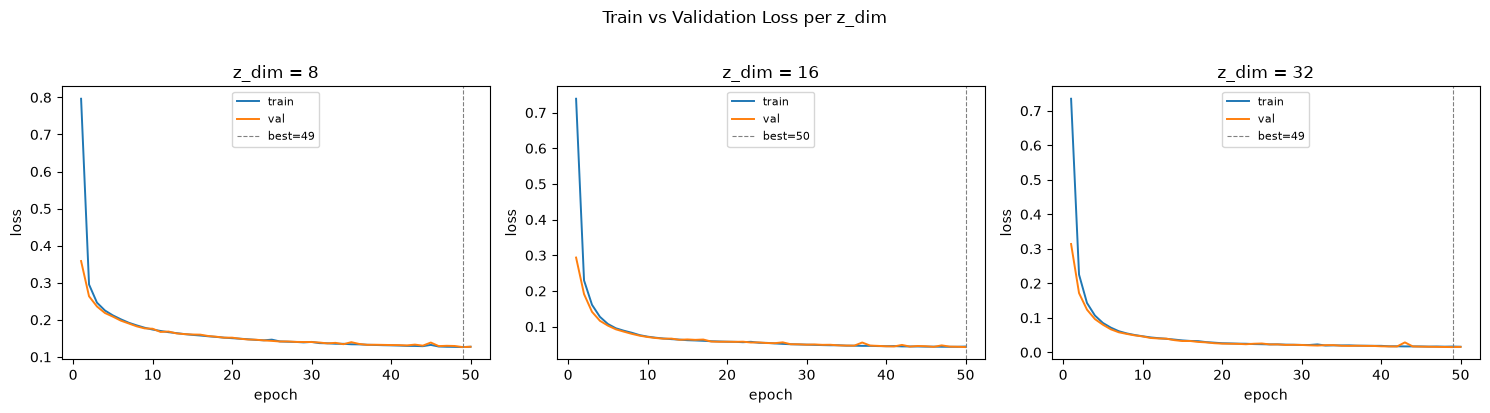

In [6]:
fig, axes = plt.subplots(1, len(Z_DIMS), figsize=(15, 4), sharey=False)
for ax, (z, hist) in zip(axes, results.items()):
    ax.plot(hist['epoch'], hist['train_loss'], label='train', linewidth=1.4)
    ax.plot(hist['epoch'], hist['val_loss'],   label='val',   linewidth=1.4)
    best_ep = int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])
    ax.axvline(best_ep, color='gray', linestyle='--', linewidth=0.8, label=f'best={best_ep}')
    ax.set_title(f'z_dim = {z}')
    ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(fontsize=8)
plt.suptitle('Train vs Validation Loss per z_dim', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Select Best z

**Trade-off**: smaller `z` compresses more (useful for anomaly detection later) but
sacrifices reconstruction quality. `z=16` typically balances both;
 adjust `BEST_Z` after inspecting the table.

In [7]:
BEST_Z = 16  # adjust after inspecting the summary table

shutil.copy(CHECKPOINTS_DIR / f'ae_z{BEST_Z}.pt', CHECKPOINTS_DIR / 'ae_best.pt')
print(f'Best checkpoint: z_dim={BEST_Z}  ->  checkpoints/ae_best.pt')

Best checkpoint: z_dim=16  ->  checkpoints/ae_best.pt


## 6. Evaluate on Test Set

In [8]:
model_best, config_best, prep_best, history_best, best_ep = load_checkpoint(
    CHECKPOINTS_DIR / 'ae_best.pt', device=DEVICE
)
model_best.eval()
evaluator = ReconstructionEvaluator(model_best, prep_best, DEVICE)

metrics = evaluator.summary_metrics(x_num_test, x_cat_test)
print(f'MSE (numeric):  {metrics["mse_numeric"]:.6f}')
for col, acc in metrics['cat_accuracy'].items():
    print(f'  Accuracy {col}: {acc:.4f}')

MSE (numeric):  0.051850
  Accuracy city: 0.9998
  Accuracy registered_via: 0.9999
  Accuracy last_payment_method_id: 0.9992


Top 10 hardest features (highest MSE):
                    feature      mse  pearson_corr
days_since_last_transaction 0.178886      0.916220
             days_to_expire 0.157058      0.939766
      is_cancel_change_flag 0.140527      0.930579
        last_third_ratio_25 0.129499      0.934267
        days_since_last_log 0.129303      0.936676
                 bd_missing 0.115466      0.941590
                tenure_days 0.113737      0.946828
       last_third_ratio_100 0.109498      0.943821
               more_than_30 0.101397      0.952169
 last_third_sum_total_songs 0.089931      0.955496


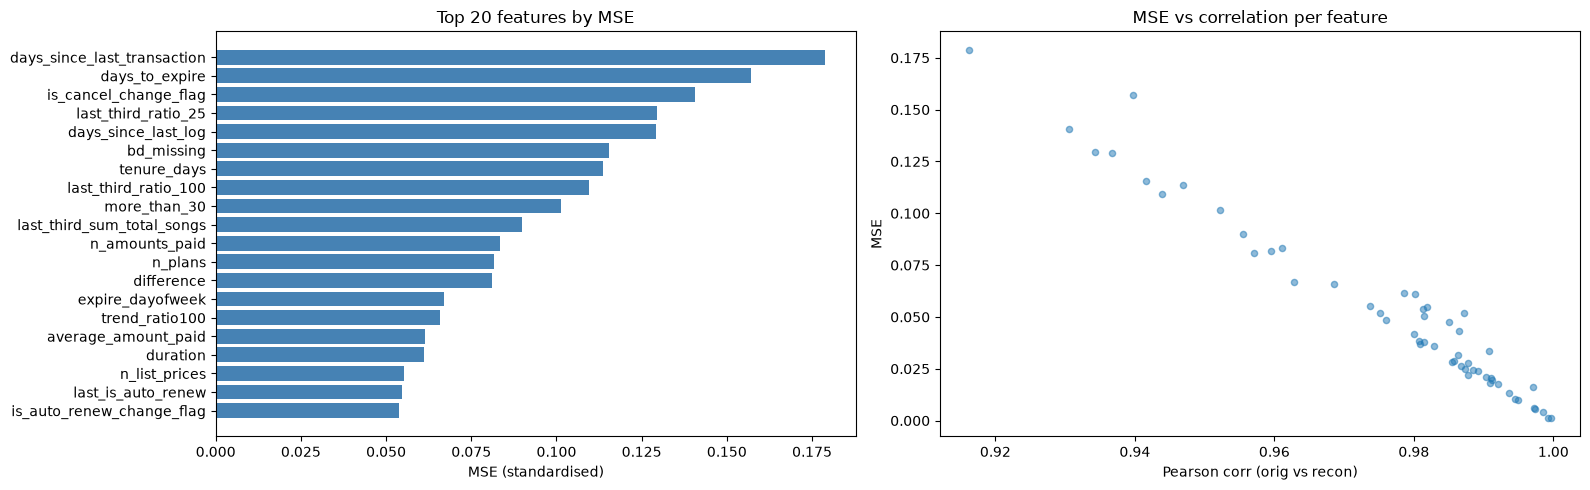

In [9]:
feat_df = evaluator.per_feature_metrics(x_num_test, x_cat_test)
print('Top 10 hardest features (highest MSE):')
print(feat_df.sort_values('mse', ascending=False).head(10).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
top20 = feat_df.nlargest(20, 'mse')
ax1.barh(top20['feature'][::-1], top20['mse'][::-1], color='steelblue')
ax1.set_xlabel('MSE (standardised)'); ax1.set_title('Top 20 features by MSE')
ax2.scatter(feat_df['pearson_corr'], feat_df['mse'], alpha=0.5, s=20)
ax2.set_xlabel('Pearson corr (orig vs recon)'); ax2.set_ylabel('MSE')
ax2.set_title('MSE vs correlation per feature')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_per_feature_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

 class      n  mean_error  median_error
normal 883630    0.042450      0.023064
 churn  87330    0.169892      0.083512


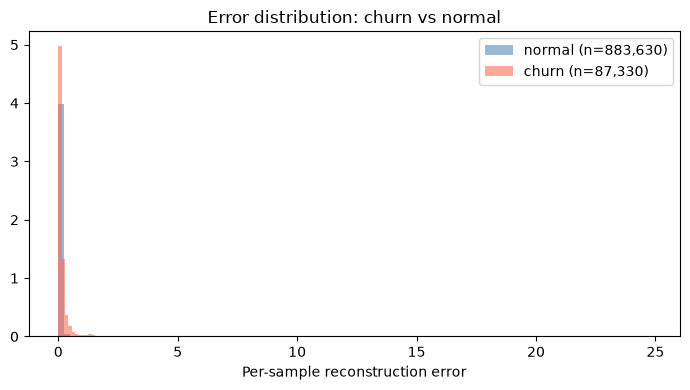

In [10]:
errors = evaluator.per_sample_error(x_num_test, x_cat_test)
class_df = evaluator.metrics_by_class(errors, y_test)
print(class_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for label, name, color in [(0, 'normal', 'steelblue'), (1, 'churn', 'tomato')]:
    ax.hist(errors[y_test == label], bins=100, alpha=0.55,
            label=f'{name} (n={int((y_test==label).sum()):,})',
            color=color, density=True)
ax.set_xlabel('Per-sample reconstruction error')
ax.set_title('Error distribution: churn vs normal')
ax.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_error_by_class.png', dpi=120, bbox_inches='tight')
plt.show()

In [11]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(x_num_test), size=8, replace=False)

panel = evaluator.sample_panel(
    x_num_test[sample_idx],
    x_cat_test[sample_idx],
    df.iloc[split['test']].iloc[sample_idx].reset_index(drop=True),
)
cols_preview = prep_best.feature_names[:15]
print('Original vs Reconstructed (first 15 features, transposed):')
print(panel[cols_preview].T.to_string())

Original vs Reconstructed (first 15 features, transposed):
                          original                                                                                            reconstructed                                                                                           
                                 0            1            2            3            4            5            6            7             0            1            2            3            4            5            6            7
bd                            43.0    29.971142    29.971142    29.971142    30.000000    36.000000    29.971142    29.971142     42.844978    30.207867    30.305833    30.034317    29.807369    36.270348    29.992481    30.071207
bd_missing                     0.0     1.000000     1.000000     1.000000     0.000000     0.000000     1.000000     1.000000      0.000000     1.000000     1.000000     1.000000     0.000000     0.000000     1.000000     1.000000
tenure_days      

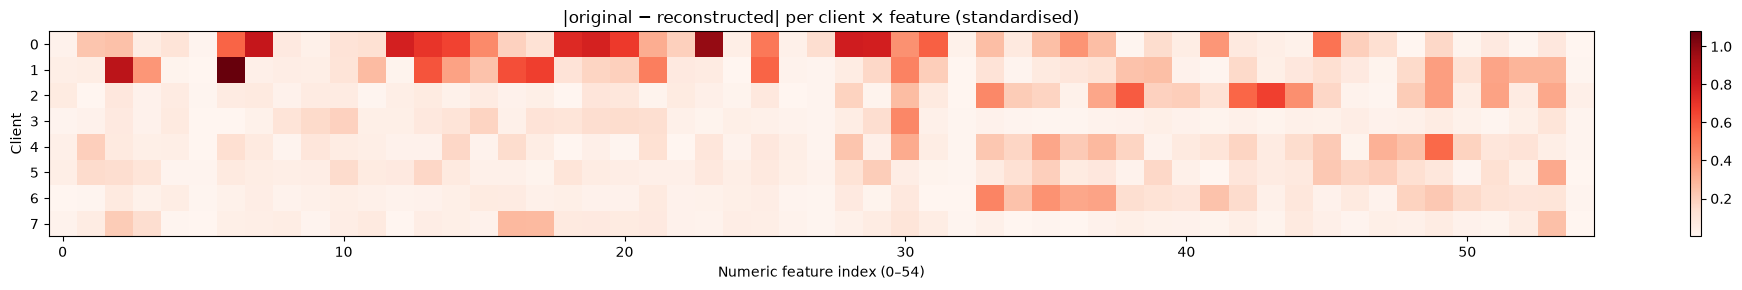

In [12]:
diff = evaluator.difference_matrix(x_num_test[sample_idx], x_cat_test[sample_idx])

fig, ax = plt.subplots(figsize=(20, 3))
im = ax.imshow(diff, aspect='auto', cmap='Reds')
ax.set_xlabel(f'Numeric feature index (0–{prep_best.numeric_dim - 1})')
ax.set_ylabel('Client'); ax.set_yticks(range(8))
ax.set_title('|original − reconstructed| per client × feature (standardised)')
plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(FIGURES_DIR / 'ae_difference_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Analysis

**Fill in after running:**

- **Which z_dim and why?** `z=16` balances compression vs reconstruction quality.
- **Hardest features?** Typically sparse / highly-skewed listening-event features.
- **Churn vs normal gap?** Churned clients tend to have higher reconstruction error because the AE learned only normal behaviour — foundation for anomaly-based detection.
- **Heatmap observation?** A small subset of features drives most of the reconstruction loss.
